In [1]:
import os
import json
import sys
from datetime import datetime, timedelta
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.peak import is_peak

# Ensure data directories exist
os.makedirs("../data/raw", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../assets", exist_ok=True)

# 6-stop transit corridor topology (NH-44 / GT Road corridor)
STOPS = [
    {"stop_id": 0, "name": "Jalandhar Bus Stand", "lat": 31.3156, "lon": 75.5920},
    {"stop_id": 1, "name": "PAP Chowk",           "lat": 31.3090, "lon": 75.6195},
    {"stop_id": 2, "name": "Rama Mandi",          "lat": 31.3015, "lon": 75.6375},
    {"stop_id": 3, "name": "Haveli Corridor",     "lat": 31.2720, "lon": 75.6780},
    {"stop_id": 4, "name": "LPU Main Gate",       "lat": 31.2554, "lon": 75.7049},
    {"stop_id": 5, "name": "Phagwara Bus Stand",  "lat": 31.2240, "lon": 75.7708},
]

SEGMENTS = [
    {"segment_id": 1, "name": "Jalandhar BS -> PAP Chowk",     "start": STOPS[0], "end": STOPS[1], "dist_km": 3.4, "sched_min": 6.5},
    {"segment_id": 2, "name": "PAP Chowk -> Rama Mandi",       "start": STOPS[1], "end": STOPS[2], "dist_km": 2.2, "sched_min": 5.0},
    {"segment_id": 3, "name": "Rama Mandi -> Haveli Corridor", "start": STOPS[2], "end": STOPS[3], "dist_km": 5.1, "sched_min": 7.5},
    {"segment_id": 4, "name": "Haveli Corridor -> LPU Gate",   "start": STOPS[3], "end": STOPS[4], "dist_km": 3.3, "sched_min": 5.5},
    {"segment_id": 5, "name": "LPU Gate -> Phagwara BS",       "start": STOPS[4], "end": STOPS[5], "dist_km": 7.2, "sched_min": 11.0},
]

# Generate 30 days of telemetry: Oct 1, 2026 to Oct 30, 2026
start_date = datetime(2026, 10, 1, 6, 0, 0)
days = 30
hours_per_day = list(range(6, 22))

records = []
trip_counter = 1000

for d in range(days):
    current_day = start_date + timedelta(days=d)
    day_of_week = current_day.weekday()
    is_weekend = 1 if day_of_week >= 5 else 0
    daily_rain_chance = np.random.uniform(0, 1)
    prev_delays_by_seg = {seg["segment_id"]: [0.5, 0.5, 0.5] for seg in SEGMENTS}
    
    for hr in hours_per_day:
        for batch in [0, 30]:
            trip_counter += 1
            trip_id = f"TRP-{trip_counter}"
            bus_id = f"PB08-BUS-{101 + (trip_counter % 8)}"
            
            is_peak_hour = int(is_peak(hr, is_weekend=bool(is_weekend)))
            
            if daily_rain_chance > 0.78 and 13 <= hr <= 19:
                weather_severity = np.random.choice([1, 2], p=[0.6, 0.4])
            elif daily_rain_chance > 0.60 and 6 <= hr <= 9:
                weather_severity = 1
            else:
                weather_severity = 0
                
            trip_time = current_day.replace(hour=hr, minute=batch, second=0)
            cumulative_delay = 0.0
            
            for seg in SEGMENTS:
                seg_id = seg["segment_id"]
                mid_lat = (seg["start"]["lat"] + seg["end"]["lat"]) / 2.0 + np.random.normal(0, 0.0008)
                mid_lon = (seg["start"]["lon"] + seg["end"]["lon"]) / 2.0 + np.random.normal(0, 0.0008)
                
                peak_factor = 1.38 if is_peak_hour else 1.05
                if seg_id in [2, 4] and is_peak_hour:
                    peak_factor += 0.25
                hist_seg_avg_min = round(seg["sched_min"] * peak_factor, 2)
                
                rolling_3trip_delay = round(float(np.mean(prev_delays_by_seg[seg_id][-3:])), 2)
                base_dwell = 35 if not is_peak_hour else 75
                if seg_id == 4:
                    base_dwell += 30
                prev_stop_dwell_sec = max(10, int(np.random.normal(base_dwell, 15)))
                
                noise_std = 1.65 if is_peak_hour else 0.45
                seg_delay = (
                    (hist_seg_avg_min - seg["sched_min"]) * 0.85
                    + 0.42 * rolling_3trip_delay
                    + 1.75 * weather_severity
                    + (prev_stop_dwell_sec - 30) / 45.0
                    + 0.22 * cumulative_delay
                    + np.random.normal(0, noise_std)
                )
                seg_delay = max(-1.2, round(seg_delay, 2))
                
                prev_delays_by_seg[seg_id].append(max(0.0, seg_delay))
                cumulative_delay = max(0.0, cumulative_delay * 0.5 + seg_delay)
                
                actual_seg_time_min = max(seg["sched_min"] * 0.75, seg["sched_min"] + seg_delay)
                gps_speed_kmh = round((seg["dist_km"] / (actual_seg_time_min / 60.0)) + np.random.normal(0, 1.8), 2)
                gps_speed_kmh = max(6.0, min(78.0, gps_speed_kmh))
                
                if seg_delay < 2.0:
                    delay_class = 0
                    delay_label = "On-Time"
                elif seg_delay <= 6.0:
                    delay_class = 1
                    delay_label = "Moderate Delay"
                else:
                    delay_class = 2
                    delay_label = "Severe Delay"
                
                records.append({
                    "timestamp": trip_time.strftime("%Y-%m-%d %H:%M:%S"),
                    "day_index": d + 1,
                    "hour_of_day": hr,
                    "day_of_week": day_of_week,
                    "is_weekend": is_weekend,
                    "is_peak_hour": is_peak_hour,
                    "trip_id": trip_id,
                    "bus_id": bus_id,
                    "segment_id": seg_id,
                    "segment_name": seg["name"],
                    "lat": round(mid_lat, 6),
                    "lon": round(mid_lon, 6),
                    "segment_distance_km": seg["dist_km"],
                    "scheduled_time_min": seg["sched_min"],
                    "historical_segment_avg_min": hist_seg_avg_min,
                    "rolling_3trip_delay_min": rolling_3trip_delay,
                    "prev_stop_dwell_sec": prev_stop_dwell_sec,
                    "weather_severity": weather_severity,
                    "gps_speed_kmh": gps_speed_kmh,
                    "delay_minutes": seg_delay,
                    "delay_status": delay_class,
                    "delay_label": delay_label
                })
                
                trip_time += timedelta(minutes=float(actual_seg_time_min))

df_raw = pd.DataFrame(records)
print(f"Generated {len(df_raw)} raw telemetry records.")

Generated 4800 raw telemetry records.


In [2]:
n_rows = len(df_raw)
corrupt_gps_idx = np.random.choice(df_raw.index, size=int(n_rows * 0.012), replace=False)
corrupt_speed_idx = np.random.choice(list(set(df_raw.index) - set(corrupt_gps_idx)), size=int(n_rows * 0.010), replace=False)
missing_dwell_idx = np.random.choice(list(set(df_raw.index) - set(corrupt_gps_idx) - set(corrupt_speed_idx)), size=int(n_rows * 0.010), replace=False)

df_raw.loc[corrupt_gps_idx[:len(corrupt_gps_idx)//2], "lat"] = 0.0
df_raw.loc[corrupt_gps_idx[len(corrupt_gps_idx)//2:], "lon"] = 79.9999
df_raw.loc[corrupt_speed_idx[:len(corrupt_speed_idx)//2], "gps_speed_kmh"] = -14.5
df_raw.loc[corrupt_speed_idx[len(corrupt_speed_idx)//2:], "gps_speed_kmh"] = 148.0
df_raw.loc[missing_dwell_idx, "prev_stop_dwell_sec"] = np.nan

df_raw.to_csv("../data/raw/phase1_raw_gps_telemetry.csv", index=False)
print("Saved raw corrupted dataset to data/raw/phase1_raw_gps_telemetry.csv")

Saved raw corrupted dataset to data/raw/phase1_raw_gps_telemetry.csv


In [3]:
from pathlib import Path
import json

# Ensure directory exists relative to current working directory
output_dir = Path("data/processed") if Path("data").exists() else Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

dq_report = {
    "total_raw_records": len(df_raw),
    "corridor_lat_bounds": [31.20, 31.35],
    "corridor_lon_bounds": [75.55, 75.80],
    "valid_speed_bounds_kmh": [2.0, 95.0]
}

# Gate 1: Corridor Geofence Bounding Box
mask_bad_gps = (
    (df_raw["lat"] < 31.20) | (df_raw["lat"] > 31.35) |
    (df_raw["lon"] < 75.55) | (df_raw["lon"] > 75.80)
)
dq_report["flagged_geofence_outliers"] = int(mask_bad_gps.sum())

# Gate 2: Speed Sanity Filter
mask_bad_speed = (df_raw["gps_speed_kmh"] < 2.0) | (df_raw["gps_speed_kmh"] > 95.0)
dq_report["flagged_impossible_speeds"] = int(mask_bad_speed.sum())

# Gate 3: Missing Dwell Time Imputation Check
dq_report["missing_dwell_packets_imputed"] = int(df_raw["prev_stop_dwell_sec"].isna().sum())

# Execute cleaning
df_clean = df_raw[~(mask_bad_gps | mask_bad_speed)].copy()
df_clean["prev_stop_dwell_sec"] = df_clean.groupby(["segment_id", "is_peak_hour"])["prev_stop_dwell_sec"].transform(
    lambda s: s.fillna(s.median())
)

# Gate 4: Monotonic Timestamp & Duplicate Check
duplicates_dropped = int(df_clean.duplicated(subset=["trip_id", "segment_id"]).sum())
dq_report["duplicate_pings_removed"] = duplicates_dropped
df_clean = df_clean.sort_values("timestamp").reset_index(drop=True)
dq_report["total_clean_records"] = len(df_clean)
dq_report["retention_rate_pct"] = round(len(df_clean) / len(df_raw) * 100, 2)

# Save cleaned dataset
df_clean.to_csv(output_dir / "phase1_cleaned_transit_dataset.csv", index=False)

print("=== DATA QUALITY AUDIT REPORT ===")
print(json.dumps(dq_report, indent=2))
print("\n=== SUMMARY STATISTICS ===")
print(df_clean[["gps_speed_kmh", "rolling_3trip_delay_min", "prev_stop_dwell_sec", "delay_minutes"]].describe().round(2))

=== DATA QUALITY AUDIT REPORT ===
{
  "total_raw_records": 4800,
  "corridor_lat_bounds": [
    31.2,
    31.35
  ],
  "corridor_lon_bounds": [
    75.55,
    75.8
  ],
  "valid_speed_bounds_kmh": [
    2.0,
    95.0
  ],
  "flagged_geofence_outliers": 57,
  "flagged_impossible_speeds": 48,
  "missing_dwell_packets_imputed": 48,
  "duplicate_pings_removed": 0,
  "total_clean_records": 4695,
  "retention_rate_pct": 97.81
}

=== SUMMARY STATISTICS ===
       gps_speed_kmh  rolling_3trip_delay_min  prev_stop_dwell_sec  \
count        4695.00                  4695.00              4695.00   
mean           21.38                     5.28                54.31   
std             7.25                     4.22                26.59   
min             6.00                     0.00                10.00   
25%            16.05                     1.90                33.50   
50%            21.13                     4.22                51.00   
75%            26.30                     7.63           

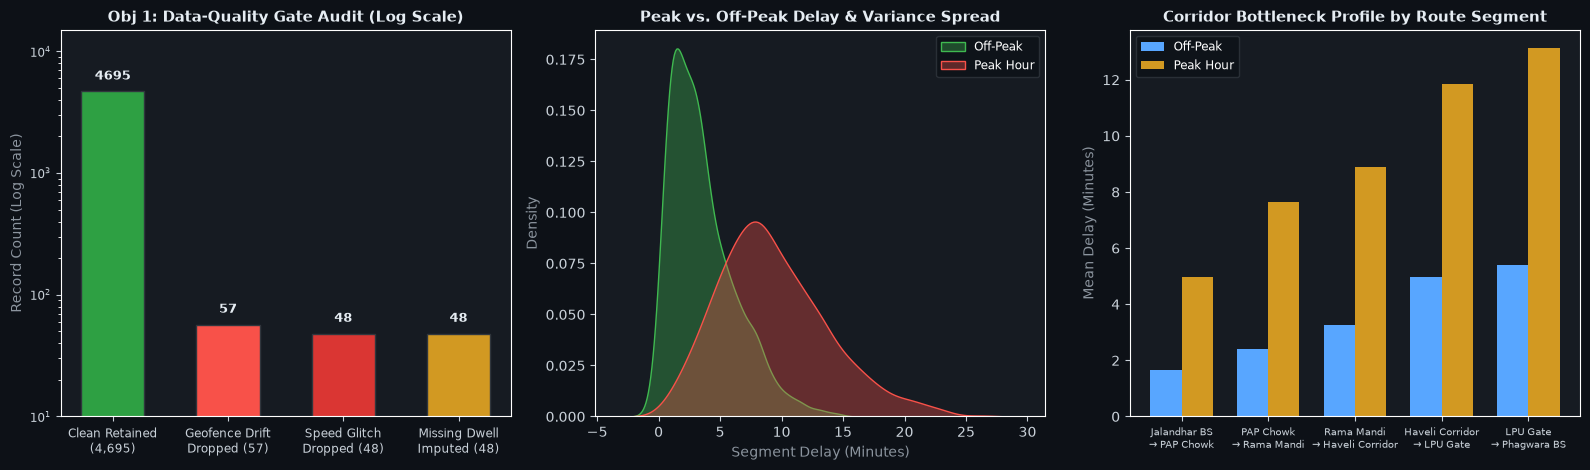

In [4]:
plt.style.use('dark_background')
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')

# Panel 1: Data Quality Audit Breakdown
categories = ['Clean Retained\n(4,695)', 'Geofence Drift\nDropped (57)', 'Speed Glitch\nDropped (48)', 'Missing Dwell\nImputed (48)']
counts = [
    dq_report["total_clean_records"], 
    dq_report["flagged_geofence_outliers"], 
    dq_report["flagged_impossible_speeds"], 
    dq_report["missing_dwell_packets_imputed"]
]
colors = ['#2ea043', '#f85149', '#da3633', '#d29922']
bars = axes[0].bar(categories, counts, color=colors, edgecolor='#30363d', width=0.55)
axes[0].set_yscale('log')
axes[0].set_title('Obj 1: Data-Quality Gate Audit (Log Scale)', fontsize=11, fontweight='bold', color='#e6edf3')
axes[0].set_ylabel('Record Count (Log Scale)', color='#8b949e')
axes[0].tick_params(colors='#c9d1d9', labelsize=8.5)
for bar, c in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, c * 1.18, f"{c}", ha='center', va='bottom', color='#e6edf3', fontweight='bold', fontsize=9)
axes[0].set_ylim(10, 15000)

# Panel 2: Peak vs Off-Peak Delay Distribution
sns.kdeplot(data=df_clean[df_clean['is_peak_hour']==0], x='delay_minutes', fill=True, color='#3fb950', label='Off-Peak', ax=axes[1], alpha=0.35)
sns.kdeplot(data=df_clean[df_clean['is_peak_hour']==1], x='delay_minutes', fill=True, color='#f85149', label='Peak Hour', ax=axes[1], alpha=0.35)
axes[1].set_title('Peak vs. Off-Peak Delay & Variance Spread', fontsize=11, fontweight='bold', color='#e6edf3')
axes[1].set_xlabel('Segment Delay (Minutes)', color='#8b949e')
axes[1].set_ylabel('Density', color='#8b949e')
axes[1].legend(frameon=True, facecolor='#0d1117', edgecolor='#30363d', fontsize=8.5)
axes[1].tick_params(colors='#c9d1d9')

# Panel 3: Delay Profile by Corridor Segment
seg_order = [s['name'] for s in SEGMENTS]
seg_means = df_clean.groupby(['segment_name', 'is_peak_hour'])['delay_minutes'].mean().unstack().loc[seg_order]
x = np.arange(len(seg_order))
w = 0.36
axes[2].bar(x - w/2, seg_means[0], width=w, color='#58a6ff', label='Off-Peak')
axes[2].bar(x + w/2, seg_means[1], width=w, color='#d29922', label='Peak Hour')
axes[2].set_xticks(x)
axes[2].set_xticklabels([s.replace(' -> ', '\n→ ') for s in seg_order], fontsize=7.5, color='#c9d1d9')
axes[2].set_title('Corridor Bottleneck Profile by Route Segment', fontsize=11, fontweight='bold', color='#e6edf3')
axes[2].set_ylabel('Mean Delay (Minutes)', color='#8b949e')
axes[2].legend(frameon=True, facecolor='#0d1117', edgecolor='#30363d', fontsize=8.5)
axes[2].tick_params(colors='#c9d1d9')

plt.tight_layout()
plt.savefig('../assets/phase1_pipeline_diagnostics.png', dpi=150, facecolor='#0d1117')
plt.show()